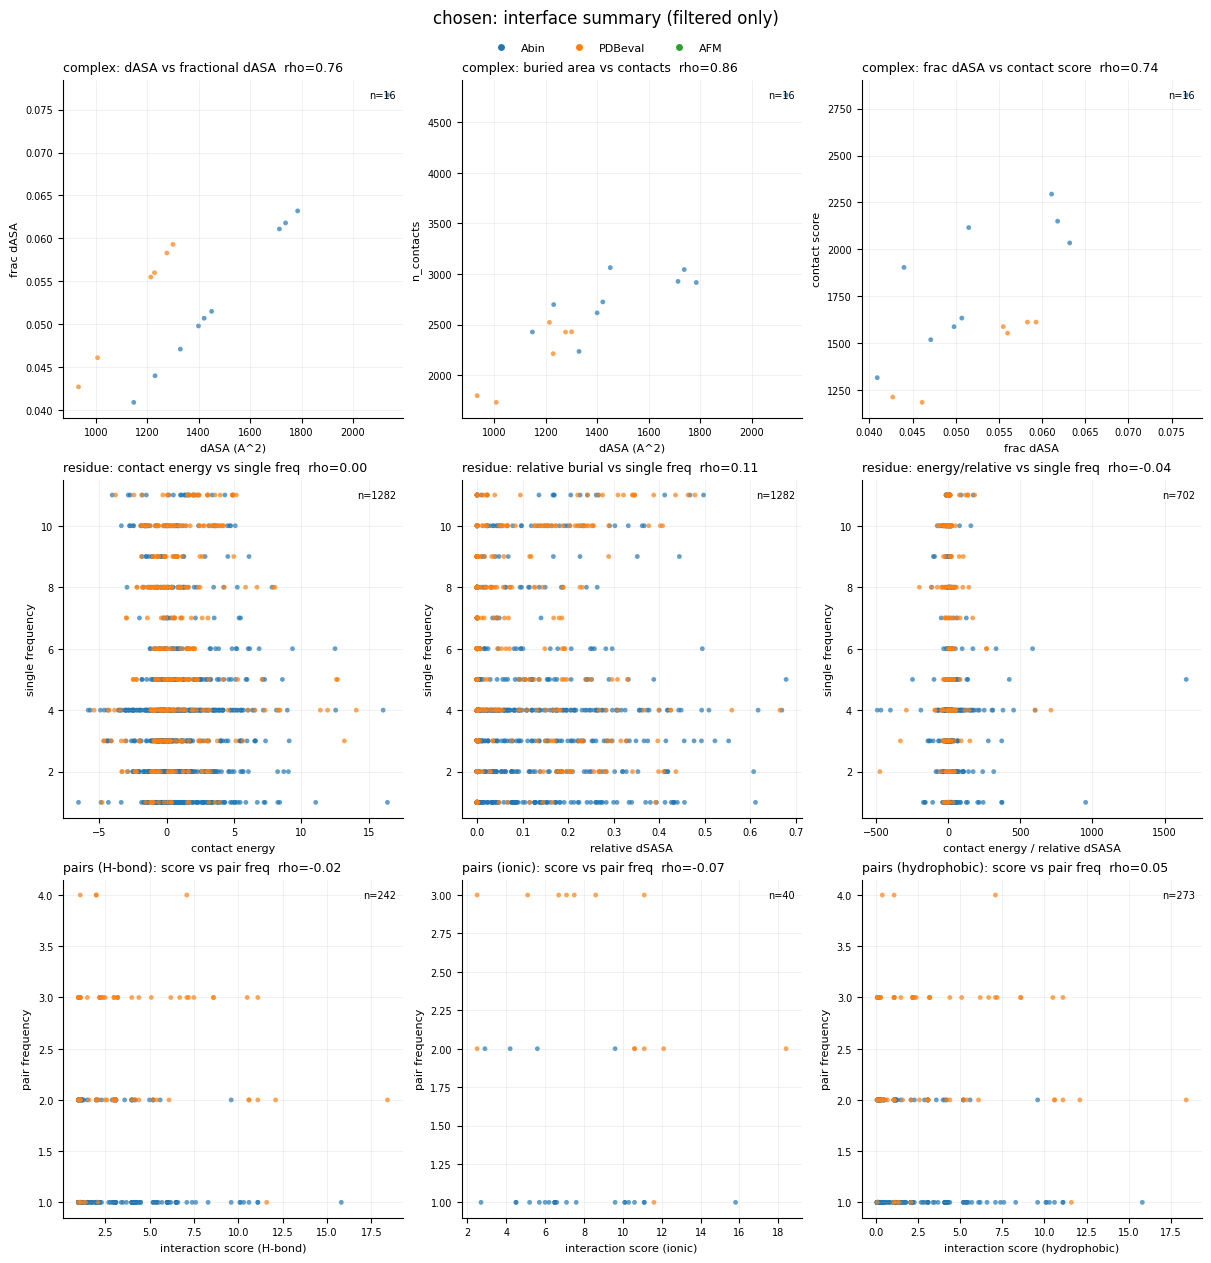

/orfeo/cephfs/scratch/area/ssenci/venvs/ml_transformers/lib64/python3.13/site-packages/matplotlib_venn/layout/venn3/pairwise.py:111: UserWarning: Circle C has zero area.
  warnings.warn("Circle C has zero area.")
/orfeo/cephfs/scratch/area/ssenci/venvs/ml_transformers/lib64/python3.13/site-packages/matplotlib_venn/layout/venn3/pairwise.py:111: UserWarning: Circle C has zero area.
  warnings.warn("Circle C has zero area.")
/orfeo/cephfs/scratch/area/ssenci/venvs/ml_transformers/lib64/python3.13/site-packages/matplotlib_venn/layout/venn3/pairwise.py:111: UserWarning: Circle C has zero area.
  warnings.warn("Circle C has zero area.")
/orfeo/cephfs/scratch/area/ssenci/venvs/ml_transformers/lib64/python3.13/site-packages/matplotlib_venn/layout/venn3/pairwise.py:111: UserWarning: Circle C has zero area.
  warnings.warn("Circle C has zero area.")
/orfeo/cephfs/scratch/area/ssenci/venvs/ml_transformers/lib64/python3.13/site-packages/matplotlib_venn/layout/venn3/pairwise.py:111: UserWarning: Ci

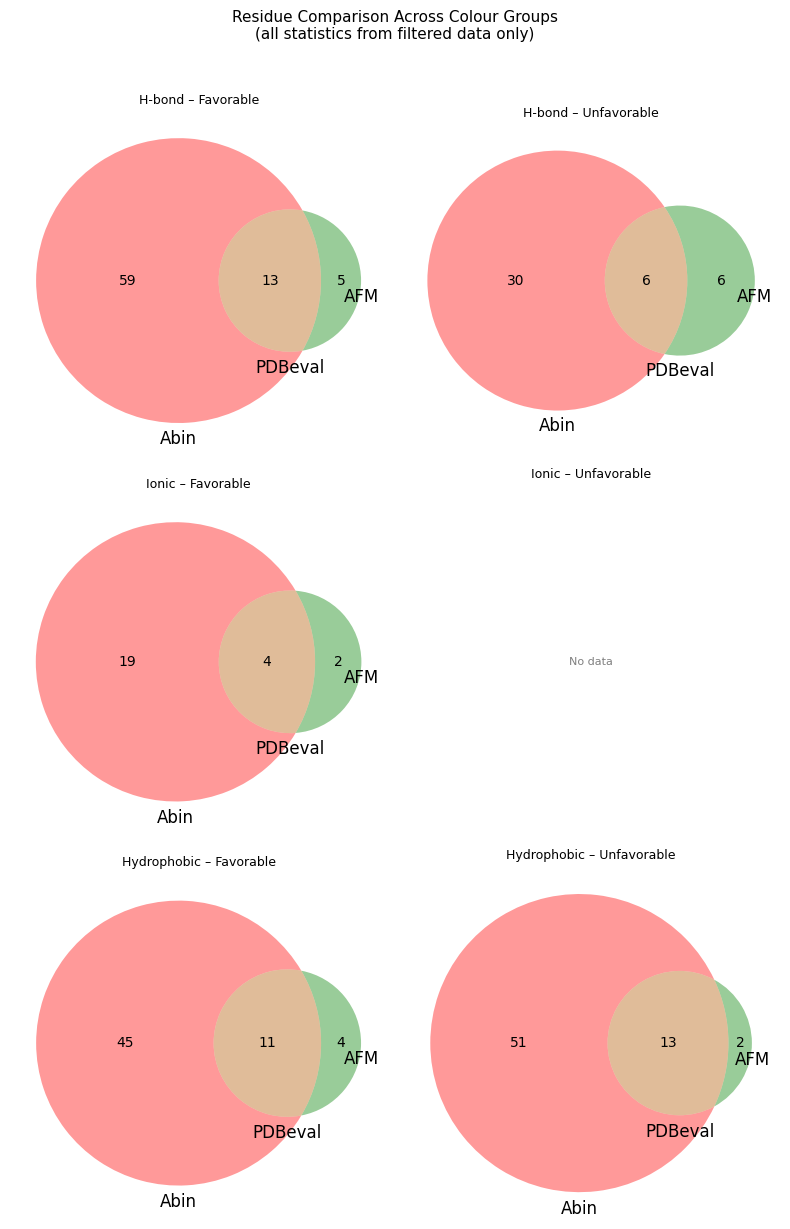


MOST STABILIZING RESIDUES  (all metrics from filtered data only)

>>> TIM-NTD_x_UHRF1-SRA_abin_emref_116  [Abin]
chain  resid resname  single_freq  contact_energy  rel_dSASA  n_partners  stab_score
    A    128     LYS            5           2.534      0.102           4      13.967
    → written to TIM-NTD_x_UHRF1-SRA_abin_emref_116_top_stabilizing_residues.tsv

>>> TIM-NTD_x_UHRF1-SRA_abin_emref_150  [Abin]
chain  resid resname  single_freq  contact_energy  rel_dSASA  n_partners  stab_score
    A    441     LYS            3           6.535      0.174          12      23.023
    A    107     ARG            3           5.533      0.199           4      19.909
    → written to TIM-NTD_x_UHRF1-SRA_abin_emref_150_top_stabilizing_residues.tsv

>>> TIM-NTD_x_UHRF1-SRA_abin_emref_19  [Abin]
chain  resid resname  single_freq  contact_energy  rel_dSASA  n_partners  stab_score
    A    200     ASP           11           4.907      0.412          13      76.239
    A    343     ARG            8 

In [3]:
import re
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import pandas as pd

try:
    from matplotlib_venn import venn3
    HAS_VENN = True
except ImportError:
    HAS_VENN = False

# ----------------------------------------------------------------------
# 1. Load + strict colour filtering (only these structures exist afterwards)
# ----------------------------------------------------------------------
groups = {
    "#1f77b4": ["TIM-NTD_x_UHRF1-SRA_abin"],
    "#ff7f0e": ["TIM-NTD_x_UHRF1-UBL_pdbeval"],
}

d = Path("data/measurements")
n = "chosen"

df_c = pd.read_csv(d / f"{n}_complex_scores.tsv", sep="\t")
df_r = pd.read_csv(d / f"{n}_residue_scores.tsv", sep="\t")
df_p = pd.read_csv(d / f"{n}_pymol_pairs.tsv", sep="\t")

def filter_and_color(df):
    def match_col(name):
        for col, pats in groups.items():
            if any(re.search(p, str(name)) for p in pats):
                return col
        return None
    df = df.copy()
    df["_color"] = df["structure"].apply(match_col)
    return df.dropna(subset=["_color"]).reset_index(drop=True)

df_c = filter_and_color(df_c)
df_r = filter_and_color(df_r)
df_p = filter_and_color(df_p)

# Merge pair frequency onto pairs (still only filtered data)
df_p_merged = pd.merge(
    df_p,
    df_r[["structure", "chain", "resid", "pair_freq", "_color"]],
    left_on=["structure", "chain_a", "resid_a"],
    right_on=["structure", "chain", "resid"],
    how="left",
    suffixes=("", "_r"),
)
if "_color_r" in df_p_merged.columns:
    df_p_merged["_color"] = df_p_merged["_color"].fillna(df_p_merged["_color_r"])

# ----------------------------------------------------------------------
# 2. Helper functions – all statistics come from the filtered frames
# ----------------------------------------------------------------------
def spear(x, y):
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 3:
        return float("nan")
    return float(np.corrcoef(
        np.argsort(np.argsort(x[m])),
        np.argsort(np.argsort(y[m]))
    )[0, 1])

def style(ax, xl, yl, t, n_val):
    ax.set_xlabel(xl, fontsize=8)
    ax.set_ylabel(yl, fontsize=8)
    ax.set_title(t, fontsize=9, loc="left")
    ax.grid(alpha=0.25, lw=0.5)
    ax.tick_params(labelsize=7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.98, 0.97, f"n={n_val}", transform=ax.transAxes,
            fontsize=7, va="top", ha="right")

def scat(ax, x, y, xl, yl, t, cols=None):
    m = np.isfinite(x) & np.isfinite(y)
    c = cols[m] if cols is not None else None
    ax.scatter(x[m], y[m], s=12, alpha=0.7, edgecolor="none", c=c)
    style(ax, xl, yl, f"{t}  rho={spear(x, y):.2f}", int(m.sum()))

# Convenience views (all filtered)
C  = lambda col: df_c[col].to_numpy(dtype=float)
R  = lambda col: df_r[col].to_numpy(dtype=float)
CC = lambda df: df["_color"].to_numpy()

cc_c = CC(df_c)
cc_r = CC(df_r)

# Interaction-type subsets – still only filtered pairs
sub_hbond = df_p_merged[df_p_merged["n_hbond"] > 0]
sub_ionic = df_p_merged[df_p_merged["n_salt_bridge"] > 0]
sub_hydro = df_p_merged[df_p_merged["n_hydrophobic_atoms"] > 0]

# ----------------------------------------------------------------------
# 3. Main 3×3 summary figure (everything computed on filtered data)
# ----------------------------------------------------------------------
fig, ax = plt.subplots(3, 3, figsize=(12, 12), constrained_layout=True)

# Complex level
scat(ax[0, 0], C("dASA_A2"), C("frac_dASA"),
     "dASA (A^2)", "frac dASA", "complex: dASA vs fractional dASA", cc_c)
scat(ax[0, 1], C("dASA_A2"), C("n_contacts"),
     "dASA (A^2)", "n_contacts", "complex: buried area vs contacts", cc_c)
scat(ax[0, 2], C("frac_dASA"), C("contact_score"),
     "frac dASA", "contact score", "complex: frac dASA vs contact score", cc_c)

# Residue level
scat(ax[1, 0], R("contact_energy"), R("single_freq"),
     "contact energy", "single frequency",
     "residue: contact energy vs single freq", cc_r)
scat(ax[1, 1], R("rel_dSASA"), R("single_freq"),
     "relative dSASA", "single frequency",
     "residue: relative burial vs single freq", cc_r)

# energy / relative burial (guard against division by zero)
rel = R("rel_dSASA")
ene = R("contact_energy")
ratio = ene / np.where(rel == 0, np.nan, rel)
scat(ax[1, 2], ratio, R("single_freq"),
     "contact energy / relative dSASA", "single frequency",
     "residue: energy/relative vs single freq", cc_r)

# Pair level
scat(ax[2, 0],
     sub_hbond["interaction_score"].to_numpy(dtype=float),
     sub_hbond["pair_freq"].to_numpy(dtype=float),
     "interaction score (H-bond)", "pair frequency",
     "pairs (H-bond): score vs pair freq",
     sub_hbond["_color"].to_numpy())
scat(ax[2, 1],
     sub_ionic["interaction_score"].to_numpy(dtype=float),
     sub_ionic["pair_freq"].to_numpy(dtype=float),
     "interaction score (ionic)", "pair frequency",
     "pairs (ionic): score vs pair freq",
     sub_ionic["_color"].to_numpy())
scat(ax[2, 2],
     sub_hydro["interaction_score"].to_numpy(dtype=float),
     sub_hydro["pair_freq"].to_numpy(dtype=float),
     "interaction score (hydrophobic)", "pair frequency",
     "pairs (hydrophobic): score vs pair freq",
     sub_hydro["_color"].to_numpy())

group_labels = {"#1f77b4": "Abin", "#ff7f0e": "PDBeval", "#2ca02c": "AFM"}
handles = [
    mlines.Line2D([], [], marker="o", color="w",
                  markerfacecolor=col, markersize=6, label=lbl)
    for col, lbl in group_labels.items()
]
fig.legend(handles=handles, loc="upper center",
           bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=8, frameon=False)
fig.suptitle(f"{n}: interface summary (filtered only)", fontsize=12, y=1.04)
fig.savefig(d / f"{n}_summary.svg", format="svg", bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# 4. Venn diagrams (also purely on filtered df_p)
# ----------------------------------------------------------------------
if HAS_VENN and not df_p.empty:
    df_p = df_p.copy()
    df_p["is_hbond"]      = df_p["n_hbond"] > 0
    df_p["is_ionic"]      = df_p["n_salt_bridge"] > 0
    df_p["is_hydrophobic"] = df_p["n_hydrophobic_atoms"] > 0

    # median computed on the filtered pairs only
    median_score = df_p["interaction_score"].median()
    df_p["is_favorable"] = df_p["interaction_score"] > median_score

    interaction_types = {
        "H-bond": "is_hbond",
        "Ionic": "is_ionic",
        "Hydrophobic": "is_hydrophobic",
    }

    fig_venn, axes_venn = plt.subplots(3, 2, figsize=(8, 12))
    color_keys  = list(group_labels.keys())
    color_names = list(group_labels.values())

    for row_idx, (itype_name, itype_col) in enumerate(interaction_types.items()):
        for col_idx, is_fav in enumerate([True, False]):
            ax_v = axes_venn[row_idx, col_idx]
            sets = []
            for ck in color_keys:
                subset = df_p[
                    (df_p["_color"] == ck) &
                    df_p[itype_col] &
                    (df_p["is_favorable"] == is_fav)
                ]
                residue_set = set(
                    subset[["chain_a", "resid_a"]].itertuples(index=False, name=None)
                )
                sets.append(residue_set)

            fav_str = "Favorable" if is_fav else "Unfavorable"
            ax_v.set_title(f"{itype_name} – {fav_str}", fontsize=9)

            if any(len(s) > 0 for s in sets):
                venn3(sets, set_labels=color_names, ax=ax_v)
            else:
                ax_v.text(0.5, 0.5, "No data", transform=ax_v.transAxes,
                          ha="center", va="center", fontsize=8, color="gray")
                ax_v.set_axis_off()

    fig_venn.suptitle(
        "Residue Comparison Across Colour Groups\n"
        "(all statistics from filtered data only)",
        fontsize=11, y=1.02
    )
    fig_venn.tight_layout()
    fig_venn.savefig(d / f"{n}_residue_venn.svg", format="svg", bbox_inches="tight")
    plt.show()

# ----------------------------------------------------------------------
# 5. Most stabilizing residues – thresholds & ranking from filtered data only
# ----------------------------------------------------------------------
def select_stabilizing_residues(
    df_r, df_p_merged,
    freq_percentile=50,
    energy_percentile=75,
    min_rel_dSASA=0.05,
):
    """
    All percentiles, medians and composite scores are computed
    exclusively on the already-filtered dataframes.
    Returns dict[structure] → ranked DataFrame of selected residues.
    """
    results = {}

    for struct, g in df_r.groupby("structure"):
        if g.empty:
            continue

        # thresholds from this complex’s filtered residues only
        freq_thr   = np.nanpercentile(g["single_freq"],    freq_percentile)
        energy_thr = np.nanpercentile(g["contact_energy"], energy_percentile)

        mask = (
            (g["single_freq"]    >= freq_thr) &
            (g["contact_energy"] >= energy_thr) &
            (g["rel_dSASA"]      >= min_rel_dSASA)
        )
        cand = g[mask].copy()
        if cand.empty:
            results[struct] = cand
            continue

        # favourable pairs also taken from the filtered merge
        pairs_of_struct = df_p_merged[df_p_merged["structure"] == struct]
        if pairs_of_struct.empty:
            fav_resids = set()
        else:
            med = pairs_of_struct["interaction_score"].median()  # filtered median
            fav = pairs_of_struct[pairs_of_struct["interaction_score"] > med]
            fav_resids = set(zip(fav["chain_a"], fav["resid_a"]))

        cand["has_fav_pair"] = cand.apply(
            lambda r: (r["chain"], r["resid"]) in fav_resids, axis=1
        )
        cand = cand[cand["has_fav_pair"]]

        # composite score – again only filtered numbers
        cand["stab_score"] = (
            cand["single_freq"] *
            cand["contact_energy"] *
            (1.0 + cand["rel_dSASA"])
        )
        cand = cand.sort_values("stab_score", ascending=False)

        results[struct] = cand[[
            "chain", "resid", "resname",
            "single_freq", "contact_energy", "rel_dSASA",
            "n_partners", "stab_score"
        ]]

    return results

selected = select_stabilizing_residues(df_r, df_p_merged)

# ----------------------------------------------------------------------
# 6. Print results for every filtered complex
# ----------------------------------------------------------------------
print("\n" + "=" * 80)
print("MOST STABILIZING RESIDUES  (all metrics from filtered data only)")
print("=" * 80)

for struct, tab in selected.items():
    colour = df_r.loc[df_r["structure"] == struct, "_color"].iloc[0]
    group_name = group_labels.get(colour, colour)

    print(f"\n>>> {struct}  [{group_name}]")
    if tab.empty:
        print("    (no residues passed the filters)")
        continue

    print(tab.head(10).to_string(index=False, float_format="%.3f"))

    out_path = d / f"{struct}_top_stabilizing_residues.tsv"
    tab.to_csv(out_path, sep="\t", index=False)
    print(f"    → written to {out_path.name}")